## Human in the Loop

In [16]:
import os 
from langchain.chat_models import init_chat_model

llm = init_chat_model(model="groq:openai/gpt-oss-120b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.4', 'langchain': '1.4.8'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x1116e3710>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x1116f00d0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [24]:
from typing import Annotated

from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from typing_extensions import TypedDict

from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

from langgraph.types import Command, interrupt

class State(TypedDict):
    messages: Annotated[list, add_messages]

graph_builder = StateGraph(State)

@tool
def human_assistance(query: str) -> str:
    """Request assistance from a human"""
    human_response = interrupt({'query':query})
    return human_response["data"]

tool = TavilySearch(max_results=2)
tools = [tool, human_assistance]
llm_with_tools = llm.bind_tools(tools)

def chatbot(state: State):
    message = llm_with_tools.invoke(state["messages"])

    # Because we will be interupting during tool execution,
    # we disable parallel tool calling to avoid repeating any
    # tool invocations when we resume.

    return {"messages":[message]}

graph_builder.add_node("chatbot", chatbot)

tool_node = ToolNode(tools=tools)
graph_builder.add_node("tools", tool_node)

graph_builder.add_conditional_edges("chatbot", tools_condition)

graph_builder.add_edge("tools","chatbot")
graph_builder.add_edge(START, "chatbot")



In [25]:
memory = MemorySaver()

graph = graph_builder.compile(checkpointer=memory)


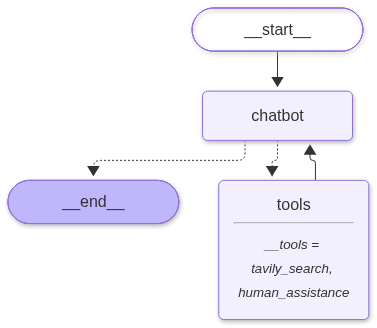

In [19]:
from IPython.display import display, Image

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    # This requires some extra dependencies and is optional
    pass


In [26]:
user_input = "I need some expert guidance and assistance for building an AI Agent. Could you request assistance for me?"
config = {"configurable":{"thread_id" : "1"}}

events = graph.stream(
    { "messages" : user_input},
    config,
    stream_mode="values"
)

for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

I need some expert guidance and assistance for building an AI Agent. Could you request assistance for me?
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_1f842a5e-d577-4db3-89e9-2f313fb47811)
 Call ID: fc_1f842a5e-d577-4db3-89e9-2f313fb47811
  Args:
    query: User requests expert guidance and assistance for building an AI Agent.
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_1f842a5e-d577-4db3-89e9-2f313fb47811)
 Call ID: fc_1f842a5e-d577-4db3-89e9-2f313fb47811
  Args:
    query: User requests expert guidance and assistance for building an AI Agent.


In [ ]:
human_response = (
    "We, the experts are here to help! We'd recommend you check out LangGraph to build your agent."
    "Is's much more reliable and extensible than simple autonomous agents"
)

human_command = Command(resume={"data":human_response})

events = graph.stream(human_command, config, stream_mode="values")


for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()




================================== Ai Message ==================================

Absolutely—happy to help you get started on building a robust AI agent! Below is a concise, step‑by‑step guide that covers the core decisions you’ll need to make, the tools you can use (including the LangGraph framework the experts recommended), and some resources to dive deeper.

---

## 1️⃣ Define the Agent’s Purpose & Scope  

| Question | Why It Matters |
|----------|----------------|
| **What problem is the agent solving?** | Determines required knowledge, data sources, and evaluation metrics. |
| **Who are the end‑users?** | Influences UI (chat UI, API, voice, etc.) and privacy/security needs. |
| **What level of autonomy?** | Fully autonomous (self‑directed loops) vs. human‑in‑the‑loop (review, approval). |
| **What constraints exist?** | Latency, cost, data compliance, domain‑specific regulations. |

*Take a minute to write a short “agent brief” that answers these questions. It will be your north‑